In [3]:

# FinGuard - Notebook 02: Feature Engineering + SMOTE

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import joblib
import json
import os
from sklearn.preprocessing import StandardScaler, LabelEncoder
from imblearn.over_sampling import SMOTE

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
os.makedirs('./data/processed', exist_ok=True)
os.makedirs('./models_saved', exist_ok=True)

In [4]:
# 1. Load Data
df = pd.read_csv('./data/raw/finguard-fraud-detection-dataset.csv')
print(f"Original shape: {df.shape}")

# 2. Drop Sensitive & Leaky Columns

# isFlaggedFraud বাদ (Data Leakage — এটা fraud detect হওয়ার পরে পাওয়া যায়)

cols_to_drop = [
    'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest',
    'nameOrig', 'nameDest',
    'isFlaggedFraud'  # <--- Leakage
]
df_clean = df.drop(cols_to_drop, axis=1)
print(f"After dropping: {df_clean.shape}")
print(f"Remaining: {df_clean.columns.tolist()}")

# 3. Type Encoding
le = LabelEncoder()
df_clean['type_encoded'] = le.fit_transform(df_clean['type'])
print(f"Type mapping: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# 4. Time Features
df_clean['hour_of_day'] = df_clean['step'] % 24
df_clean['day_of_week'] = (df_clean['step'] // 24) % 7

# 5. Amount Transforms
df_clean['log_amount'] = np.log1p(df_clean['amount'])
df_clean['sqrt_amount'] = np.sqrt(df_clean['amount'])

Original shape: (6362620, 11)
After dropping: (6362620, 4)
Remaining: ['step', 'type', 'amount', 'isFraud']
Type mapping: {'CASH_IN': np.int64(0), 'CASH_OUT': np.int64(1), 'DEBIT': np.int64(2), 'PAYMENT': np.int64(3), 'TRANSFER': np.int64(4)}


In [5]:
#6. Amount Flags
df_clean['is_high_value'] = (df_clean['amount'] > 200000).astype(int)
df_clean['is_very_high_value'] = (
    df_clean['amount'] > df_clean['amount'].quantile(0.99)
).astype(int)

# 7. Transaction Type One-Hot 
for t in ['CASH_OUT', 'TRANSFER', 'PAYMENT', 'CASH_IN', 'DEBIT']:
    df_clean[f'is_{t.lower()}'] = (df_clean['type'] == t).astype(int)

# 8. Ratio Features
df_clean['type_frequency'] = df_clean.groupby('type')['step'].transform('count') / len(df_clean)
df_clean['amount_vs_type_avg'] = df_clean['amount'] / (
    df_clean.groupby('type')['amount'].transform('mean') + 1
)
df_clean['amount_vs_step_avg'] = df_clean['amount'] / (
    df_clean.groupby('step')['amount'].transform('mean') + 1
)

# 9. Duplicate Amount Pattern
df_clean['amount_count'] = df_clean.groupby('amount')['step'].transform('count')
df_clean['is_duplicate_amount'] = (df_clean['amount_count'] > 1).astype(int)

# 10. Final Feature List (NO LEAKAGE)
feature_columns = [
    'step', 'amount', 'type_encoded',
    'hour_of_day', 'day_of_week',
    'log_amount', 'sqrt_amount',
    'is_high_value', 'is_very_high_value',
    'is_cash_out', 'is_transfer', 'is_payment', 'is_cash_in', 'is_debit',
    'type_frequency',
    'amount_vs_type_avg', 'amount_vs_step_avg',
    'amount_count', 'is_duplicate_amount'
]

print(f"\nFinal features ({len(feature_columns)}):")
for f in feature_columns:
    print(f"  - {f}")


Final features (19):
  - step
  - amount
  - type_encoded
  - hour_of_day
  - day_of_week
  - log_amount
  - sqrt_amount
  - is_high_value
  - is_very_high_value
  - is_cash_out
  - is_transfer
  - is_payment
  - is_cash_in
  - is_debit
  - type_frequency
  - amount_vs_type_avg
  - amount_vs_step_avg
  - amount_count
  - is_duplicate_amount


In [6]:
#   11. TIME-BASED Split (leakage-free)   
df_sorted = df_clean.sort_values('step').reset_index(drop=True)
split_idx = int(len(df_sorted) * 0.8)

train_df = df_sorted.iloc[:split_idx].copy()
test_df  = df_sorted.iloc[split_idx:].copy()

X_train = train_df[feature_columns].reset_index(drop=True)
y_train = train_df['isFraud'].reset_index(drop=True)
X_test  = test_df[feature_columns].reset_index(drop=True)
y_test  = test_df['isFraud'].reset_index(drop=True)

print(f"\n=== Time-based Split ===")
print(f"Train: {len(X_train):,} | fraud: {y_train.sum():,} ({y_train.mean()*100:.4f}%)")
print(f"Test:  {len(X_test):,}  | fraud: {y_test.sum():,} ({y_test.mean()*100:.4f}%)")

#    12. SMOTE (on train ONLY)   
print("\n=== Applying SMOTE ===")
print(f"Before SMOTE: {y_train.value_counts().to_dict()}")

smote = SMOTE(
    sampling_strategy=0.1,   # fraud হবে non-fraud এর 10%
    random_state=42,
    k_neighbors=5
)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print(f"After SMOTE: {y_train_res.value_counts().to_dict()}")
print(f"Train size: {len(X_train_res):,}")


=== Time-based Split ===
Train: 5,090,096 | fraud: 3,959 (0.0778%)
Test:  1,272,524  | fraud: 4,254 (0.3343%)

=== Applying SMOTE ===
Before SMOTE: {0: 5086137, 1: 3959}
After SMOTE: {0: 5086137, 1: 508613}
Train size: 5,594,750


In [8]:
# 13. Scaling
numeric_features = [
    'step', 'amount', 'log_amount', 'sqrt_amount',
    'hour_of_day', 'day_of_week',
    'amount_vs_type_avg', 'amount_vs_step_avg',
    'amount_count', 'type_frequency'
]

scaler = StandardScaler()
X_train_scaled = X_train_res.copy()
X_test_scaled  = X_test.copy()
X_train_scaled[numeric_features] = scaler.fit_transform(X_train_res[numeric_features])
X_test_scaled[numeric_features]  = scaler.transform(X_test[numeric_features])

In [9]:
# 14. Save
X_train_res.to_csv('./data/processed/X_train_resampled.csv', index=False)
X_test.to_csv('./data/processed/X_test.csv', index=False)
y_train_res.to_csv('./data/processed/y_train_resampled.csv', index=False)
y_test.to_csv('./data/processed/y_test.csv', index=False)

X_train_scaled.to_csv('./data/processed/X_train_scaled.csv', index=False)
X_test_scaled.to_csv('./data/processed/X_test_scaled.csv', index=False)

joblib.dump(scaler, './models_saved/scaler.pkl')
with open('./models_saved/feature_columns.json', 'w') as f:
    json.dump(feature_columns, f, indent=4)

print("\n✅ Processed data saved!")


✅ Processed data saved!


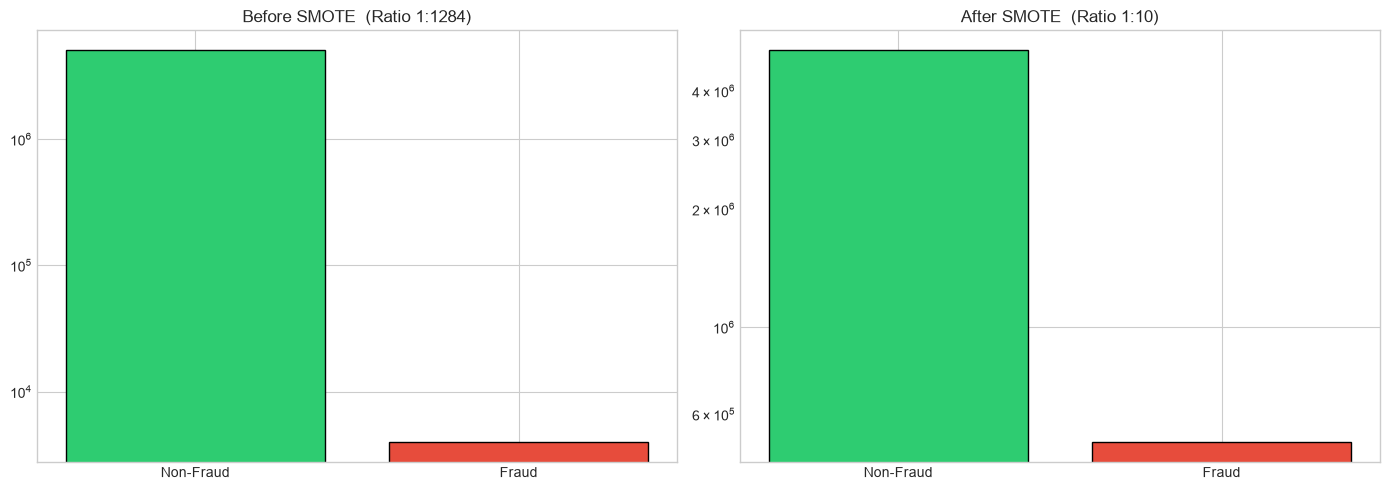

In [10]:
# 15. Visualize SMOTE
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
before = y_train.value_counts()
after  = y_train_res.value_counts()

axes[0].bar(['Non-Fraud', 'Fraud'], [before[0], before[1]],
            color=['#2ecc71', '#e74c3c'], edgecolor='black')
axes[0].set_title(f'Before SMOTE  (Ratio 1:{before[0]//before[1]})')
axes[0].set_yscale('log')

axes[1].bar(['Non-Fraud', 'Fraud'], [after[0], after[1]],
            color=['#2ecc71', '#e74c3c'], edgecolor='black')
axes[1].set_title(f'After SMOTE  (Ratio 1:{after[0]//after[1]})')
axes[1].set_yscale('log')

plt.tight_layout()
plt.savefig('./reports/figures/smote_effect.png', dpi=300, bbox_inches='tight')
plt.show()